In [1]:
.libPaths(c('/home/jbos/.conda/envs/vcfR', '/home/jbos/.conda/envs/vcfR/lib/R/library', '/software/apps/r/conda3-4.4.1/lib/R/library','/home/jbos/R/x86_64-conda-linux-gnu-library/4.4'))

In [3]:
library(vegan)
library(dendextend)
library(dplyr)
library(sp)
library(sf)
library(ggplot2)
library(cowplot)

In [4]:
#Calculate great circle distances from lat/lons
wide_dists <- function(sites){
    x<-st_as_sf(sites,coords=c('LONGITUDE','LATITUDE'))
    x<-st_set_crs(x,4326)
    d <- st_distance(x)
    colnames(d)<-sites$Ind
    rownames(d)<-sites$Ind
    d<-as.data.frame(d)
    return(d)
}

In [5]:
#Input: site string
#Output: island tag
island_sel <- function(string){
  x<-substr(string, start = 1, stop = 3)
  return(x)
}

In [6]:
make_long<-function(ibs_mat,col3){
    indices<-which(upper.tri(ibs_mat, diag=FALSE), arr.ind=TRUE)
    df_long <- data.frame(
      row<-rownames(ibs_mat)[indices[,1]],
      col<-colnames(ibs_mat)[indices[,2]],
      value<-ibs_mat[indices]
    )
    colnames(df_long)<-c('IndA','IndB',col3)
    df_long$ID<-paste(df_long$IndA,df_long$IndB,sep="_")
    return(df_long)
    }

In [7]:
ibs_matrix<-as.matrix(read.table('/scratch/jbos/ANGSD_IBS/philippines_acropora.ibsMat'))

In [8]:
dim(ibs_matrix)

[1] 390 390

In [9]:
cov_matrix<-as.matrix(read.table('/home/jbos/Philippines_revisions/philippines_acropora.covMat'))

In [10]:
dim(cov_matrix)

[1] 390 390

In [11]:
e<-eigen(cov_matrix)

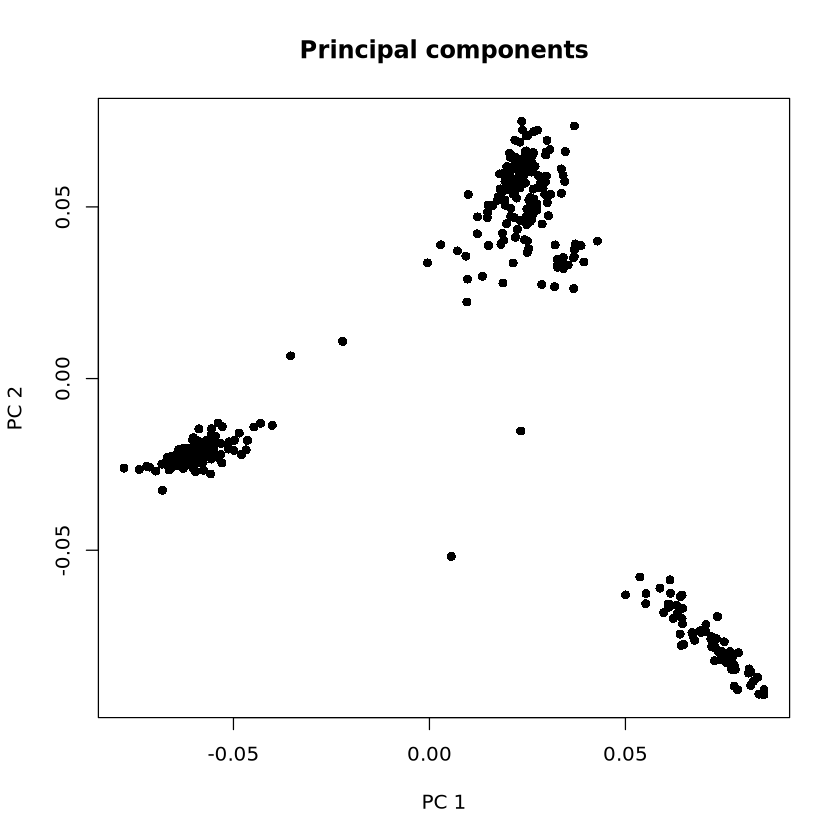

In [12]:
plot(e$vectors[,1:2],lwd=2,ylab="PC 2",xlab="PC 1",main="Principal components",pch=16)

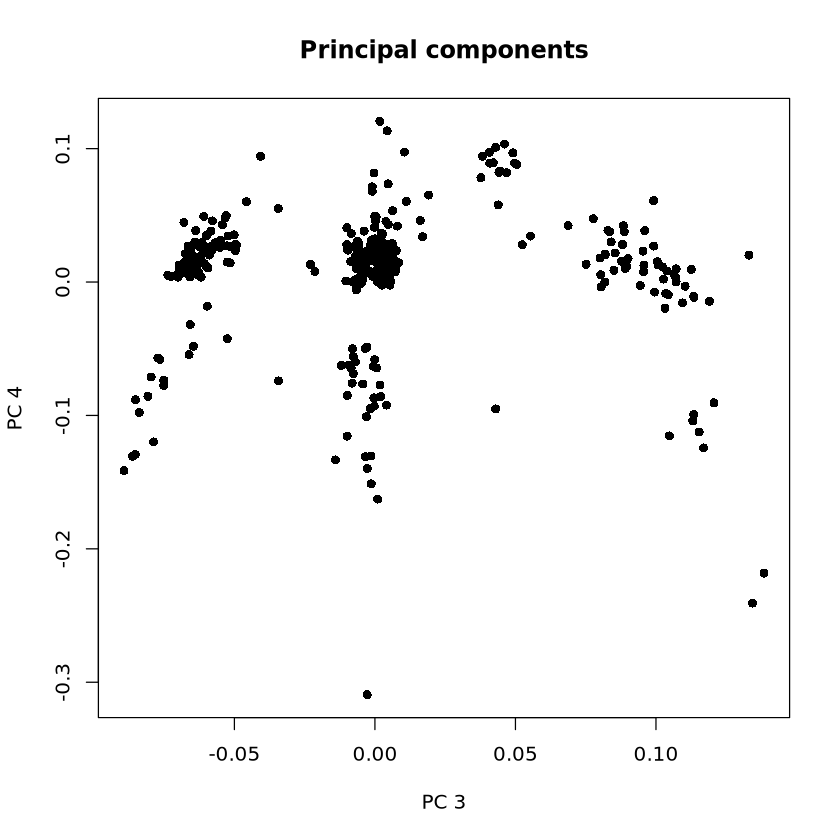

In [13]:
plot(e$vectors[,3:4],lwd=2,ylab="PC 4",xlab="PC 3",main="Principal components",pch=16)

In [13]:
bamfiles<-read.table('/home/jbos/Philippines_revisions/filtered_acropora_bams.txt')

In [14]:
nrow(bamfiles)

[1] 390

In [15]:
#Little function to get sample names from BAMfiles
bamnames<-function(bam){
    a<-strsplit(bam,'sorted/')[[1]][2]
    b<-strsplit(a,'.b')[[1]][1]
    return(b)
    }

In [16]:
indlist<-apply(bamfiles,FUN=bamnames,MARGIN=1)

In [17]:
inds1<-read.table('/home/jbos/Atenuis_Philippines/other_data/taxa1_dfa.txt')[,1]
inds2<-read.table('/home/jbos/Atenuis_Philippines/other_data/taxa2_dfa.txt')[,1]
inds3<-read.table('/home/jbos/Atenuis_Philippines/other_data/taxa3_dfa.txt')[,1]
inds4<-read.table('/home/jbos/Atenuis_Philippines/other_data/taxa4_dfa.txt')[,1]

In [18]:
inds<-as.data.frame(matrix(nrow=nrow(ibs_matrix),ncol=1))
inds$IND<-indlist
inds$taxon<-0

In [19]:
inds$taxon[inds$IND %in% inds1]<-1
inds$taxon[inds$IND %in% inds2]<-2
inds$taxon[inds$IND %in% inds3]<-3
inds$taxon[inds$IND %in% inds4]<-4
inds$taxon<-as.factor(inds$taxon)

In [20]:
table(inds$taxon)


  0   1   2   3   4 
 92 120  71  56  51 

In [21]:
rownames(ibs_matrix) <- indlist
colnames(ibs_matrix) <- indlist

In [22]:
ibs_dist <- as.dist(ibs_matrix)

In [23]:
pcoa_res<-capscale(ibs_dist ~ 1)

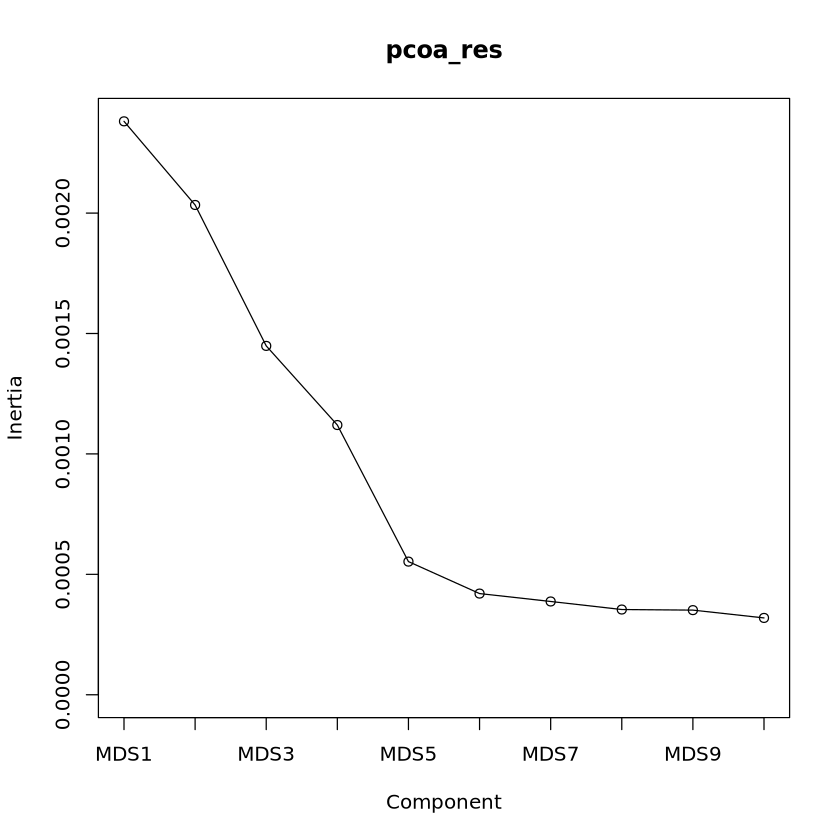

In [24]:
screeplot(pcoa_res, type="line")

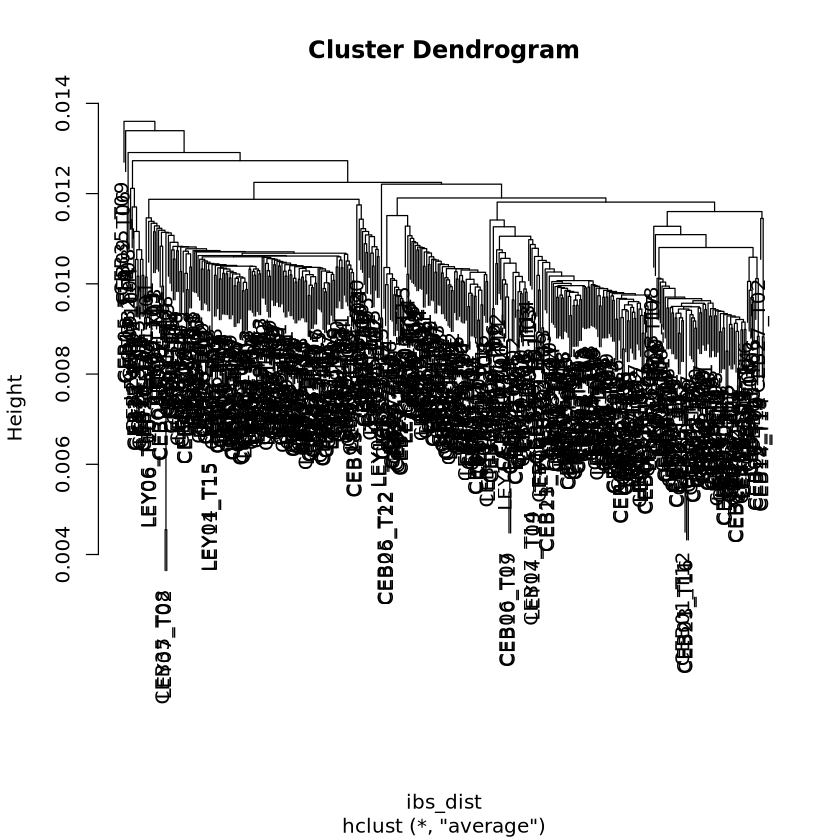

In [25]:
set.seed(42)
hc<-hclust(ibs_dist,method='av')
plot(hc)

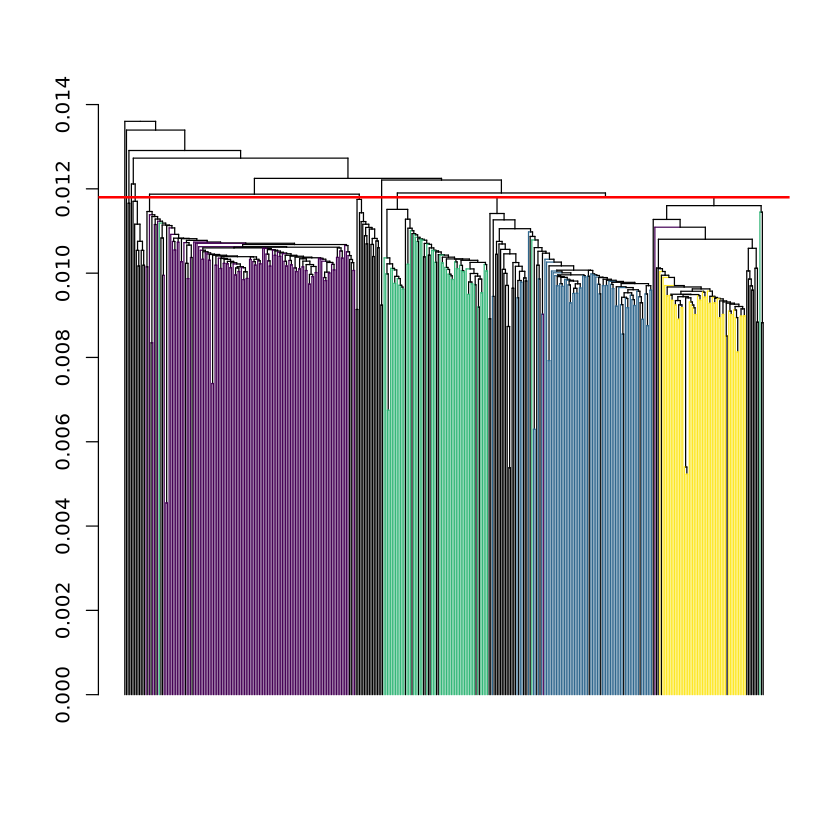

In [26]:
dend<-as.dendrogram(hc)
dend_order<-order.dendrogram(dend)
taxa<-inds$taxon[dend_order]
color_map<-c("0"="black","1"="#440154FF","2"="#31688EFF","3"="#35B779FF","4"="#FDE725FF")
colors<-color_map[taxa]
#dend<-color_labels(dend, col=colors)
dend<-color_branches(dend,col=colors)
plot(dend,leaflab = "none")
abline(h=0.0118, col="red", lwd=2)

In [27]:
# High-res JPEG
jpeg("dendrogram.jpg", width = 10, height = 7, units = "in", res = 300)
dend <- as.dendrogram(hc)
dend_order <- order.dendrogram(dend)
taxa <- inds$taxon[dend_order]
color_map <- c("0"="black","1"="#440154FF","2"="#31688EFF","3"="#35B779FF","4"="#FDE725FF")
colors <- color_map[taxa]
dend <- color_branches(dend, col=colors)
plot(dend, leaflab="none")
abline(h=0.0118, col="red", lwd=2)
dev.off()

# PDF
pdf("dendrogram.pdf", width = 10, height = 7)
dend <- as.dendrogram(hc)
dend_order <- order.dendrogram(dend)
taxa <- inds$taxon[dend_order]
colors <- color_map[taxa]
dend <- color_branches(dend, col=colors)
plot(dend, leaflab="none")
abline(h=0.0118, col="red", lwd=2)
dev.off()

pdf 
  2

pdf 
  2

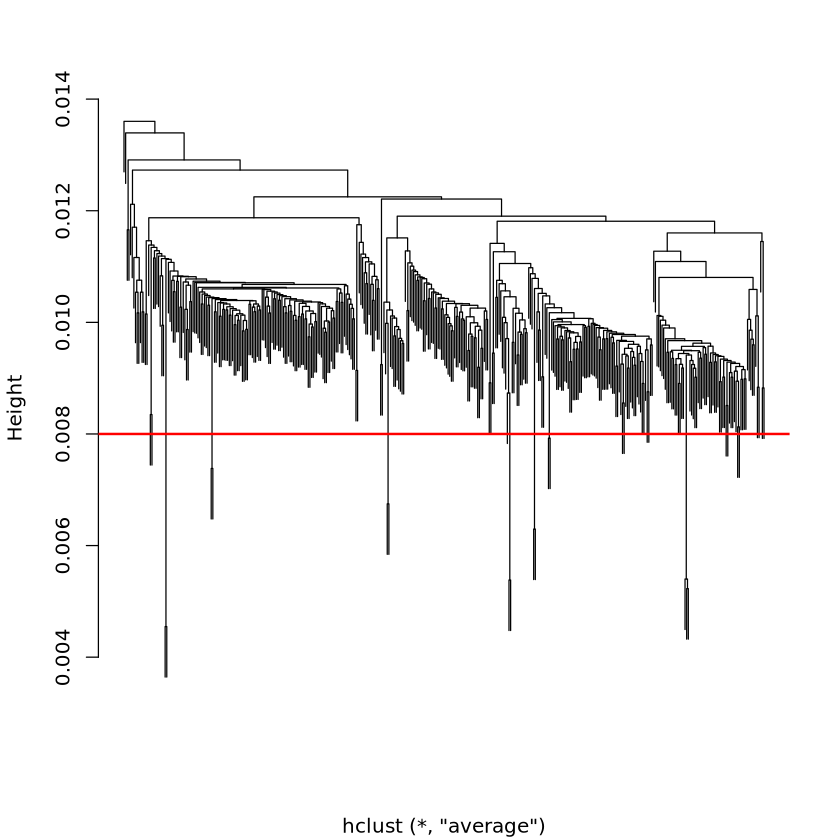

In [39]:
hc_ave<-hclust(ibs_dist,method="ave")
plot(hc_ave,labels=FALSE,xlab='',main='')
abline(h=0.008, col="red", lwd=2)

In [44]:
labels_reordered<-inds$IND[dend_order]
clones<-cutree(hc_ave,h=0.008)
for(i in unique(clones)) {
  samples_in_cluster <- names(clones[clones==i])
  if(length(samples_in_cluster) > 1) {
    print(paste("Cluster", i, ":", paste(samples_in_cluster, collapse = ", ")))
  }
}

[1] "Cluster 8 : CEB01_T11, CEB01_T12, CEB23_T16"
[1] "Cluster 39 : CEB05_T12, CEB26_T22"
[1] "Cluster 48 : CEB06_T07, CEB10_T19"
[1] "Cluster 65 : CEB07_T14, LEY14_T09"
[1] "Cluster 116 : CEB11_T13, CEB23_T17"
[1] "Cluster 274 : CEB35_T08, LEY07_T02"
[1] "Cluster 291 : LEY04_T15, LEY11_T15"


In [41]:
tip_x <- match(labels(as.dendrogram(hc_ave)), labels_reordered)
named_samples <- c(
  "CEB01_T11"="E",
  "CEB05_T12"="D",
  "CEB07_T14"="C",
  "CEB35_T08"="A",
  "LEY04_T15"="B"
)

In [42]:
dend_ave <- as.dendrogram(hc_ave)

[1] 0 0 0 0 0 0

In [54]:
jpeg("hclust_relatedness_labeled.jpg", width = 10, height = 7, units = "in", res = 500)
plot(hc_ave,labels=FALSE,xlab='',main='')
for (sample in names(named_samples)) {
  x_pos <- which(labels_reordered_ave == sample)
  leaf_index <- -which(hc_ave$labels == sample)  # negative index = leaf in hc_ave$merge
  merge_row <- which(hc_ave$merge[,1] == leaf_index | hc_ave$merge[,2] == leaf_index)
  y_pos <- hc_ave$height[merge_row]
  text(x=x_pos, y=y_pos-0.0012, labels=named_samples[sample],
       col="blue", xpd=TRUE,cex=1.5)
}

abline(h=0.008, col="red", lwd=2)
dev.off()

pdf 
  2

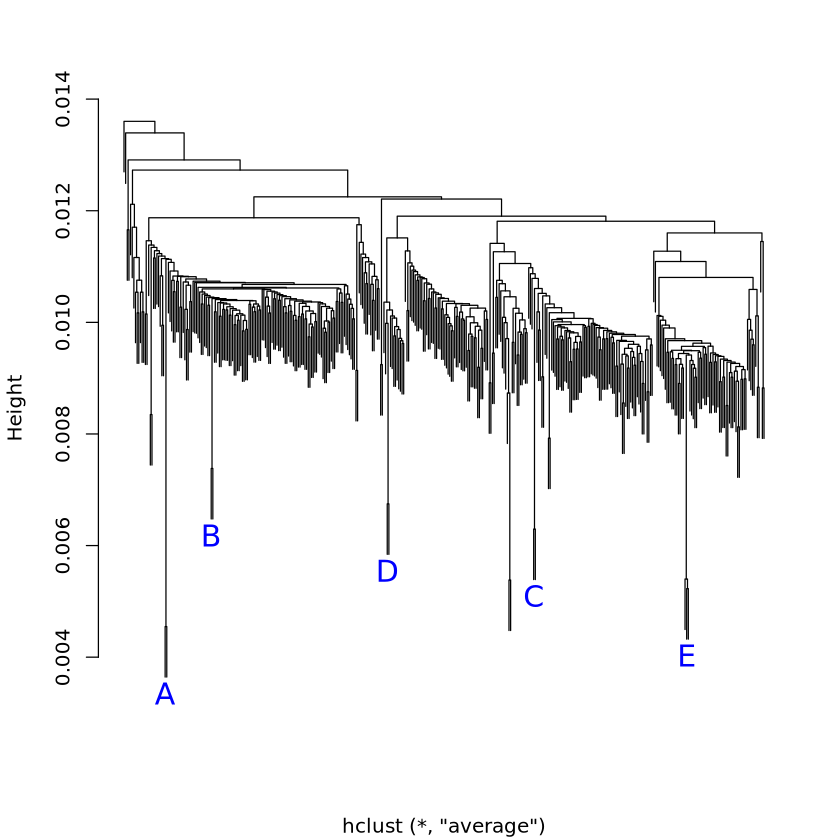

In [55]:
plot(hc_ave,labels=FALSE,xlab='',main='')
for (sample in names(named_samples)) {
  x_pos <- which(labels_reordered_ave == sample)
  leaf_index <- -which(hc_ave$labels == sample)  # negative index = leaf in hc_ave$merge
  merge_row <- which(hc_ave$merge[,1] == leaf_index | hc_ave$merge[,2] == leaf_index)
  y_pos <- hc_ave$height[merge_row]
  text(x=x_pos, y=y_pos-0.0012, labels=named_samples[sample],
       col="blue", xpd=TRUE,cex=1.5)
}


In [36]:
head(labels(as.dendrogram(hc_ave)))
head(labels_reordered)
which(labels_reordered=="CEB01_T11")

[1] "CEB35_T09" "CEB09_T06" "CEB05_T19" "CEB18_T14" "CEB32_T08" "CEB09_T04"

[1] "CEB35_T09" "CEB09_T06" "CEB05_T19" "CEB18_T14" "CEB32_T08" "CEB09_T04"

[1] 343

In [27]:
groups<-cutree(hc,h=0.0118)

In [28]:
table(groups)

groups
  1   2   3   4   5   6   7   8   9  10  11 
128 100  68  64  15   2   8   1   1   1   2 

In [29]:
inds$hctaxon<-groups

In [30]:
table(inds$taxon, inds$hctaxon)
rowSums(table(inds$taxon, inds$hctaxon))
118/120
71/71
53/56
51/51

   
      1   2   3   4   5   6   7   8   9  10  11
  0   9  27  15  11  15   2   8   1   1   1   2
  1 118   1   1   0   0   0   0   0   0   0   0
  2   0  71   0   0   0   0   0   0   0   0   0
  3   1   1   1  53   0   0   0   0   0   0   0
  4   0   0  51   0   0   0   0   0   0   0   0

0   1   2   3   4 
 92 120  71  56  51

[1] 0.9833333

[1] 1

[1] 0.9464286

[1] 1

In [31]:
ibs_grp1<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_1/taxon1.ibsMat'))))
ibs_grp2<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_2/taxon2.ibsMat'))))
ibs_grp3<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_3/taxon3.ibsMat'))))
ibs_grp4<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_4/taxon4.ibsMat'))))

In [32]:
ibs_cebu1<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_1_cebu/taxon1.ibsMat'))))
ibs_cebu2<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_2_cebu/taxon2.ibsMat'))))
ibs_cebu3<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_3_cebu/taxon3.ibsMat'))))
ibs_cebu4<-as.matrix(as.dist(as.matrix(read.table('/scratch/jbos/ANGSD_Atenuis_4_cebu/taxon4.ibsMat'))))

In [33]:
rownames(ibs_grp1)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_grp1)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_grp2)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_grp2)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_grp3)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_grp3)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_grp4)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_grp4)<-sapply(read.table('/home/jbos/Philippines_revisions/Acropora_taxon4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

In [34]:
rownames(ibs_cebu1)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_cebu1)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_cebu2)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_cebu2)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_cebu3)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_cebu3)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(ibs_cebu4)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(ibs_cebu4)<-sapply(read.table('/home/jbos/Philippines_revisions/acro_cebu4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

In [35]:
inds1_cebu<-colnames(ibs_cebu1)
inds2_cebu<-colnames(ibs_cebu2)
inds3_cebu<-colnames(ibs_cebu3)
inds4_cebu<-colnames(ibs_cebu4)

In [36]:
pops1<-as.data.frame(as.matrix(inds1))
pops2<-as.data.frame(as.matrix(inds2))
pops3<-as.data.frame(as.matrix(inds3))
pops4<-as.data.frame(as.matrix(inds4))

pops1_cebu<-as.data.frame(as.matrix(inds1_cebu))
pops2_cebu<-as.data.frame(as.matrix(inds2_cebu))
pops3_cebu<-as.data.frame(as.matrix(inds3_cebu))
pops4_cebu<-as.data.frame(as.matrix(inds4_cebu))

In [37]:
colnames(pops1)<-'Ind'
colnames(pops2)<-'Ind'
colnames(pops3)<-'Ind'
colnames(pops4)<-'Ind'

colnames(pops1_cebu)<-'Ind'
colnames(pops2_cebu)<-'Ind'
colnames(pops3_cebu)<-'Ind'
colnames(pops4_cebu)<-'Ind'

In [38]:
#Add population factors to each genind. Here, we define a sampling site as a population
pops1$pop<-as.factor(unlist(lapply(strsplit(inds1,"_"), head, 1)))
pops2$pop<-as.factor(unlist(lapply(strsplit(inds2,"_"), head, 1)))
pops3$pop<-as.factor(unlist(lapply(strsplit(inds3,"_"), head, 1)))
pops4$pop<-as.factor(unlist(lapply(strsplit(inds4,"_"), head, 1)))

pops1_cebu$pop<-as.factor(unlist(lapply(strsplit(inds1_cebu,"_"), head, 1)))
pops2_cebu$pop<-as.factor(unlist(lapply(strsplit(inds2_cebu,"_"), head, 1)))
pops3_cebu$pop<-as.factor(unlist(lapply(strsplit(inds3_cebu,"_"), head, 1)))
pops4_cebu$pop<-as.factor(unlist(lapply(strsplit(inds4_cebu,"_"), head, 1)))

In [39]:
#Import site locations with lat/lons
sites <- read.csv('/home/jbos/Atenuis_Philippines/metadat/all_Atenuis_sites.csv')
metadat<-read.csv('/home/jbos/Atenuis_Philippines/metadat/metadata_shoredist.csv')

In [40]:
colnames(sites)<-c('LONGITUDE','LATITUDE','pop')

In [41]:
#Create dataframe of sites on Cebu island (exluding Camotes, which were originally labeled as Cebu)
Ceb_real <- sites[sites$LONGITUDE<124.25,3]

In [42]:
write.table(Ceb_real,'/home/jbos/Philippines_revisions/cebu_sites.txt',quote=FALSE,row.names=FALSE)

In [43]:
#For each taxon, keep only sites including at least one individual from that taxon
sites1<-left_join(pops1,sites)
sites2<-left_join(pops2,sites)
sites3<-left_join(pops3,sites)
sites4<-left_join(pops4,sites)

sites1_cebu<-left_join(pops1_cebu,sites)
sites2_cebu<-left_join(pops2_cebu,sites)
sites3_cebu<-left_join(pops3_cebu,sites)
sites4_cebu<-left_join(pops4_cebu,sites)

Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`
Joining with `by = join_by(pop)`


In [44]:
#Make wide form dataframes of distance between sites
dists1<-as.matrix(wide_dists(sites1))
dists2<-as.matrix(wide_dists(sites2))
dists3<-as.matrix(wide_dists(sites3))
dists4<-as.matrix(wide_dists(sites4))

In [45]:
#Make wide form dataframes of distance between sites, Cebu only
dists_cebu1<-as.matrix(wide_dists(sites1_cebu))
dists_cebu2<-as.matrix(wide_dists(sites2_cebu))
dists_cebu3<-as.matrix(wide_dists(sites3_cebu))
dists_cebu4<-as.matrix(wide_dists(sites4_cebu))

In [46]:
#Take log of distances for Mantel tests
log_dists1<-as.matrix(log(dists1+0.01))
log_dists2<-as.matrix(log(dists2+0.01))
log_dists3<-as.matrix(log(dists3+0.01))
log_dists4<-as.matrix(log(dists4+0.01))

In [132]:
#Mantel test, inappropriately applied
set.seed(42)
mantel(ibs_grp1,dists1)

mantel(ibs_cebu1,dists_cebu1)


Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_grp1, ydis = dists1) 

Mantel statistic r: 0.04012 
      Significance: 0.196 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0581 0.0760 0.0903 0.1150 
Permutation: free
Number of permutations: 999



Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_cebu1, ydis = dists_cebu1) 

Mantel statistic r: 0.1108 
      Significance: 0.023 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0739 0.0955 0.1072 0.1295 
Permutation: free
Number of permutations: 999


In [133]:
#Mantel test, inappropriately applied
set.seed(42)
mantel(ibs_grp2,dists2)

mantel(ibs_cebu2,dists_cebu2)


Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_grp2, ydis = dists2) 

Mantel statistic r: 0.09219 
      Significance: 0.046 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0708 0.0889 0.1044 0.1300 
Permutation: free
Number of permutations: 999



Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_cebu2, ydis = dists_cebu2) 

Mantel statistic r: 0.05932 
      Significance: 0.235 

Upper quantiles of permutations (null model):
  90%   95% 97.5%   99% 
0.113 0.153 0.176 0.205 
Permutation: free
Number of permutations: 999


In [134]:
#Mantel test, inappropriately applied
set.seed(42)
mantel(ibs_grp3,dists3)

mantel(ibs_cebu3,dists_cebu3)


Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_grp3, ydis = dists3) 

Mantel statistic r: 0.1107 
      Significance: 0.003 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0478 0.0634 0.0799 0.0897 
Permutation: free
Number of permutations: 999



Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_cebu3, ydis = dists_cebu3) 

Mantel statistic r: 0.08437 
      Significance: 0.068 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0700 0.0919 0.1100 0.1316 
Permutation: free
Number of permutations: 999


In [135]:
#Mantel test, inappropriately applied
set.seed(42)
mantel(ibs_grp4,dists4)

mantel(ibs_cebu4,dists_cebu4)


Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_grp4, ydis = dists4) 

Mantel statistic r: -0.0356 
      Significance: 0.735 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0738 0.0959 0.1179 0.1374 
Permutation: free
Number of permutations: 999



Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_cebu4, ydis = dists_cebu4) 

Mantel statistic r: -0.06187 
      Significance: 0.901 

Upper quantiles of permutations (null model):
   90%    95%  97.5%    99% 
0.0645 0.0833 0.1047 0.1198 
Permutation: free
Number of permutations: 999


In [47]:
ibs_cladocopium<-as.matrix(read.table('/home/jbos/Philippines_revisions/philippines_cladocopium.ibsMat'))

In [48]:
nrow(ibs_cladocopium)

[1] 363

In [49]:
bamfiles_clad<-read.table('/home/jbos/Philippines_revisions/filtered_cladocopium_bams98.txt')

In [50]:
indlist_clad<-apply(bamfiles_clad,FUN=bamnames,MARGIN=1)

In [51]:
pops_clad<-as.data.frame(as.matrix(indlist_clad))
colnames(pops_clad)<-'Ind'
pops_clad$pop<-as.factor(unlist(lapply(strsplit(indlist_clad,"_"), head, 1)))

In [52]:
#For each taxon, keep only sites including at least one individual from that taxon
sites_clad<-left_join(pops_clad,sites)

Joining with `by = join_by(pop)`


In [53]:
#Make wide form dataframes of distance between sites
dists_clad<-as.matrix(wide_dists(sites_clad))

In [54]:
#Fudge some non zero distances for Mantel tests
dists_clad_nonzero<-dists_clad+0.01

In [55]:
#Take log of distances for Mantel tests
log_dists_clad<-as.matrix(log(dists_clad_nonzero))

In [56]:
#Mantel test, inappropriately applied
set.seed(42)
mantel(ibs_cladocopium,log_dists_clad)


Mantel statistic based on Pearson's product-moment correlation 

Call:
mantel(xdis = ibs_cladocopium, ydis = log_dists_clad) 

Mantel statistic r: 0.01593 
      Significance: 0.003 

Upper quantiles of permutations (null model):
    90%     95%   97.5%     99% 
0.00719 0.00901 0.01099 0.01344 
Permutation: free
Number of permutations: 999


In [57]:
#Read in Cladocopium per Acropora taxon
clad1<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium1/clad1.ibsMat'))
clad2<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium2/clad2.ibsMat'))
clad3<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium3/clad3.ibsMat'))
clad4<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium4/clad4.ibsMat'))

clad1_cebu<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium1_cebu/clad1.ibsMat'))
clad2_cebu<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium2_cebu/clad2.ibsMat'))
clad3_cebu<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium3_cebu/clad3.ibsMat'))
clad4_cebu<-as.matrix(read.table('/scratch/jbos/ANGSD_Philippines_Cladocopium4_cebu/clad4.ibsMat'))

In [58]:
rownames(clad1)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad1)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad2)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad2)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad3)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad3)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad4)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad4)<-sapply(read.table('/home/jbos/Philippines_revisions/Cladocopium_taxon4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

In [59]:
rownames(clad1_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad1_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu1.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad2_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad2_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu2.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad3_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad3_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu3.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

rownames(clad4_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)
colnames(clad4_cebu)<-sapply(read.table('/home/jbos/Philippines_revisions/clad_cebu4.txt')$V1,FUN=bamnames,USE.NAMES=FALSE)

In [60]:
#Make IBS data long form
ibs_long1<-make_long(ibs_grp1,'IBS_dist')
ibs_long2<-make_long(ibs_grp2,'IBS_dist')
ibs_long3<-make_long(ibs_grp3,'IBS_dist')
ibs_long4<-make_long(ibs_grp4,'IBS_dist')

ibs_cebu_long1<-make_long(ibs_cebu1,'IBS_dist')
ibs_cebu_long2<-make_long(ibs_cebu2,'IBS_dist')
ibs_cebu_long3<-make_long(ibs_cebu3,'IBS_dist')
ibs_cebu_long4<-make_long(ibs_cebu4,'IBS_dist')

ibs_clad_long1<-make_long(clad1,'IBS_dist')
ibs_clad_long2<-make_long(clad2,'IBS_dist')
ibs_clad_long3<-make_long(clad3,'IBS_dist')
ibs_clad_long4<-make_long(clad4,'IBS_dist')

ibs_clad_cebu_long1<-make_long(clad1_cebu,'IBS_dist')
ibs_clad_cebu_long2<-make_long(clad2_cebu,'IBS_dist')
ibs_clad_cebu_long3<-make_long(clad3_cebu,'IBS_dist')
ibs_clad_cebu_long4<-make_long(clad4_cebu,'IBS_dist')

In [61]:
#Make distance long form
dists_long1<-make_long(dists1,'dist')
dists_long2<-make_long(dists2,'dist')
dists_long3<-make_long(dists3,'dist')
dists_long4<-make_long(dists4,'dist')

dists_cebu_long1<-make_long(dists_cebu1,'dist')
dists_cebu_long2<-make_long(dists_cebu2,'dist')
dists_cebu_long3<-make_long(dists_cebu3,'dist')
dists_cebu_long4<-make_long(dists_cebu4,'dist')

In [62]:
#Get log distances
dists_long1$logdist<-log(dists_long1$dist+0.01)
dists_long2$logdist<-log(dists_long2$dist+0.01)
dists_long3$logdist<-log(dists_long3$dist+0.01)
dists_long4$logdist<-log(dists_long4$dist+0.01)

dists_cebu_long1$logdist<-log(dists_cebu_long1$dist+0.01)
dists_cebu_long2$logdist<-log(dists_cebu_long2$dist+0.01)
dists_cebu_long3$logdist<-log(dists_cebu_long3$dist+0.01)
dists_cebu_long4$logdist<-log(dists_cebu_long4$dist+0.01)

In [63]:
merge1<-inner_join(ibs_long1,dists_long1,by='ID')
merge2<-inner_join(ibs_long2,dists_long2,by='ID')
merge3<-inner_join(ibs_long3,dists_long3,by='ID')
merge4<-inner_join(ibs_long4,dists_long4,by='ID')

merge_cebu1<-inner_join(ibs_cebu_long1,dists_cebu_long1,by='ID')
merge_cebu2<-inner_join(ibs_cebu_long2,dists_cebu_long2,by='ID')
merge_cebu3<-inner_join(ibs_cebu_long3,dists_cebu_long3,by='ID')
merge_cebu4<-inner_join(ibs_cebu_long4,dists_cebu_long4,by='ID')

In [64]:
merge_clad1<-inner_join(ibs_clad_long1,dists_long1,by='ID')
merge_clad2<-inner_join(ibs_clad_long2,dists_long2,by='ID')
merge_clad3<-inner_join(ibs_clad_long3,dists_long3,by='ID')
merge_clad4<-inner_join(ibs_clad_long4,dists_long4,by='ID')

merge_clad_cebu1<-inner_join(ibs_clad_cebu_long1,dists_cebu_long1,by='ID')
merge_clad_cebu2<-inner_join(ibs_clad_cebu_long2,dists_cebu_long2,by='ID')
merge_clad_cebu3<-inner_join(ibs_clad_cebu_long3,dists_cebu_long3,by='ID')
merge_clad_cebu4<-inner_join(ibs_clad_cebu_long4,dists_cebu_long4,by='ID')

In [65]:
colnames(merge_clad2)

[1] "IndA.x"   "IndB.x"   "IBS_dist" "ID"       "IndA.y"   "IndB.y"   "dist"    
[8] "logdist"

In [66]:
#Calculate point estimates of slopes in one and two dimensions
m1<-summary(lm(IBS_dist ~ logdist,dat=merge1))$coefficients[2,1]
m2<-summary(lm(IBS_dist ~ logdist,dat=merge2))$coefficients[2,1]
m3<-summary(lm(IBS_dist ~ logdist,dat=merge3))$coefficients[2,1]
m4<-summary(lm(IBS_dist ~ logdist,dat=merge4))$coefficients[2,1]

m1_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu1))$coefficients[2,1]
m2_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu2))$coefficients[2,1]
m3_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu3))$coefficients[2,1]
m4_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu4))$coefficients[2,1]

m1_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad1))$coefficients[2,1]
m2_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad2))$coefficients[2,1]
m3_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad3))$coefficients[2,1]
m4_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad4))$coefficients[2,1]

m1_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu1))$coefficients[2,1]
m2_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu2))$coefficients[2,1]
m3_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu3))$coefficients[2,1]
m4_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu4))$coefficients[2,1]

In [67]:
#Calculate standard errors of IBD slopes in one and two dimensions for each taxon. 
se1<-summary(lm(IBS_dist ~ logdist,dat=merge1))$coefficients[2,2]
se2<-summary(lm(IBS_dist ~ logdist,dat=merge2))$coefficients[2,2]
se3<-summary(lm(IBS_dist ~ logdist,dat=merge3))$coefficients[2,2]
se4<-summary(lm(IBS_dist ~ logdist,dat=merge4))$coefficients[2,2]

se1_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu1))$coefficients[2,2]
se2_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu2))$coefficients[2,2]
se3_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu3))$coefficients[2,2]
se4_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_cebu4))$coefficients[2,2]

se1_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad1))$coefficients[2,2]
se2_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad2))$coefficients[2,2]
se3_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad3))$coefficients[2,2]
se4_clad<-summary(lm(IBS_dist ~ logdist,dat=merge_clad4))$coefficients[2,2]

se1_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu1))$coefficients[2,2]
se2_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu2))$coefficients[2,2]
se3_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu3))$coefficients[2,2]
se4_clad_ceb<-summary(lm(IBS_dist ~ dist,dat=merge_clad_cebu4))$coefficients[2,2]

In [68]:
#Calculate distribution of slopes
set.seed(42)
m1s<-rnorm(1000, mean=m1, sd=se1)
m2s<-rnorm(1000, mean=m2, sd=se2)
m3s<-rnorm(1000, mean=m3, sd=se3)
m4s<-rnorm(1000, mean=m4, sd=se4)

m1s_ceb<-rnorm(1000, mean=m1_ceb, sd=se1_ceb)
m2s_ceb<-rnorm(1000, mean=m2_ceb, sd=se2_ceb)
m3s_ceb<-rnorm(1000, mean=m3_ceb, sd=se3_ceb)
m4s_ceb<-rnorm(1000, mean=m4_ceb, sd=se4_ceb)

m1s_clad<-rnorm(1000, mean=m1_clad, sd=se1_clad)
m2s_clad<-rnorm(1000, mean=m2_clad, sd=se2_clad)
m3s_clad<-rnorm(1000, mean=m3_clad, sd=se3_clad)
m4s_clad<-rnorm(1000, mean=m4_clad, sd=se4_clad)

m1s_clad_ceb<-rnorm(1000, mean=m1_clad_ceb, sd=se1_clad_ceb)
m2s_clad_ceb<-rnorm(1000, mean=m2_clad_ceb, sd=se2_clad_ceb)
m3s_clad_ceb<-rnorm(1000, mean=m3_clad_ceb, sd=se3_clad_ceb)
m4s_clad_ceb<-rnorm(1000, mean=m4_clad_ceb, sd=se4_clad_ceb)

In [69]:
#Summarize percent of IBD slopes greater than zero, 1D Acropora
print('taxon 1')
table(m1s_ceb>0)

print('taxon 2')
table(m2s_ceb>0)

print('taxon 3')
table(m3s_ceb>0)

print('taxon 4')
table(m4s_ceb>0)

[1] "taxon 1"



TRUE 
1000 

[1] "taxon 2"



FALSE  TRUE 
   23   977 

[1] "taxon 3"



FALSE  TRUE 
    5   995 

[1] "taxon 4"



FALSE  TRUE 
  961    39 

In [70]:
#Summarize percent of IBD slopes greater than zero, 1D Cladocopium
print('taxon 1')
table(m1s_clad_ceb>0)

print('taxon 2')
table(m2s_clad_ceb>0)

print('taxon 3')
table(m3s_clad_ceb>0)

print('taxon 4')
table(m4s_clad_ceb>0)

[1] "taxon 1"



TRUE 
1000 

[1] "taxon 2"



FALSE  TRUE 
    2   998 

[1] "taxon 3"



TRUE 
1000 

[1] "taxon 4"



TRUE 
1000 

In [71]:
#Summarize percent of IBD slopes greater than zero, 2D
print('taxon 1')
table(m1s>0)

print('taxon 2')
table(m2s>0)

print('taxon 3')
table(m3s>0)

print('taxon 4')
table(m4s>0)

[1] "taxon 1"



FALSE  TRUE 
  746   254 

[1] "taxon 2"



FALSE  TRUE 
  607   393 

[1] "taxon 3"



TRUE 
1000 

[1] "taxon 4"



FALSE  TRUE 
    5   995 

In [72]:
#Summarize percent of IBD slopes greater than zero, 2D
print('taxon 1')
table(m1s_clad>0)

print('taxon 2')
table(m2s_clad>0)

print('taxon 3')
table(m3s_clad>0)

print('taxon 4')
table(m4s_clad>0)

[1] "taxon 1"



TRUE 
1000 

[1] "taxon 2"



TRUE 
1000 

[1] "taxon 3"



TRUE 
1000 

[1] "taxon 4"



TRUE 
1000 

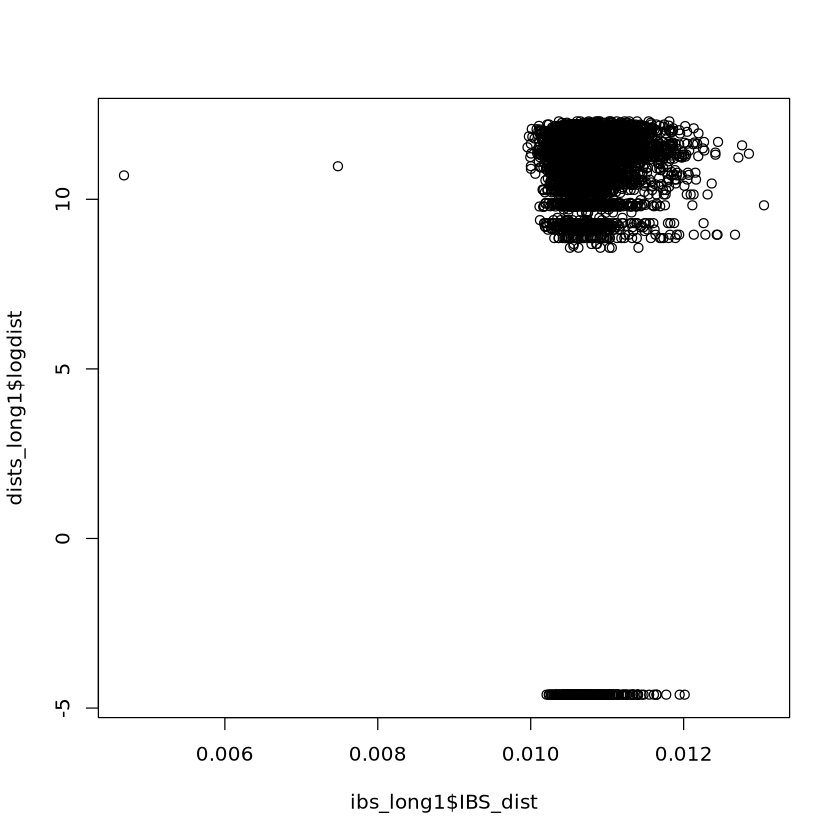

In [76]:
plot(ibs_long1$IBS_dist,dists_long1$logdist)

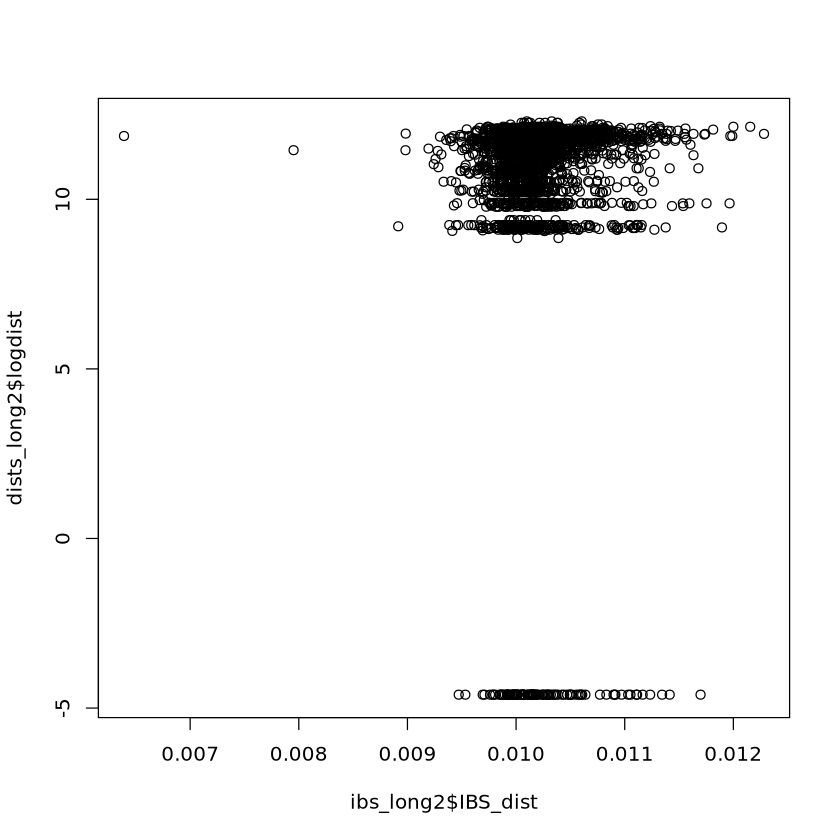

In [77]:
plot(ibs_long2$IBS_dist,dists_long2$logdist)

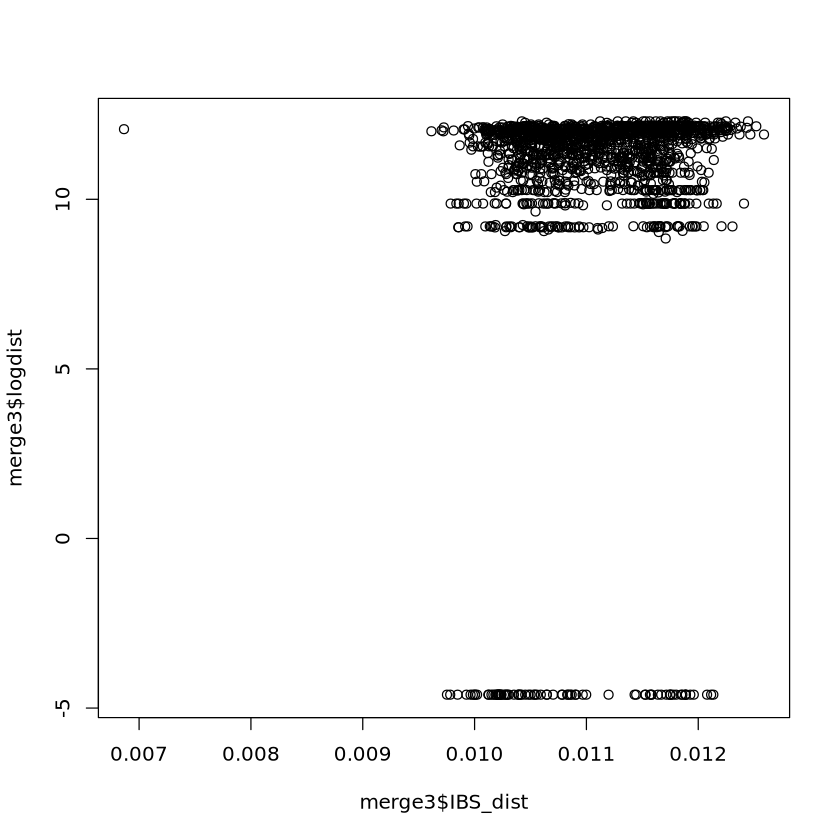

In [87]:
plot(merge3$IBS_dist,merge3$logdist)

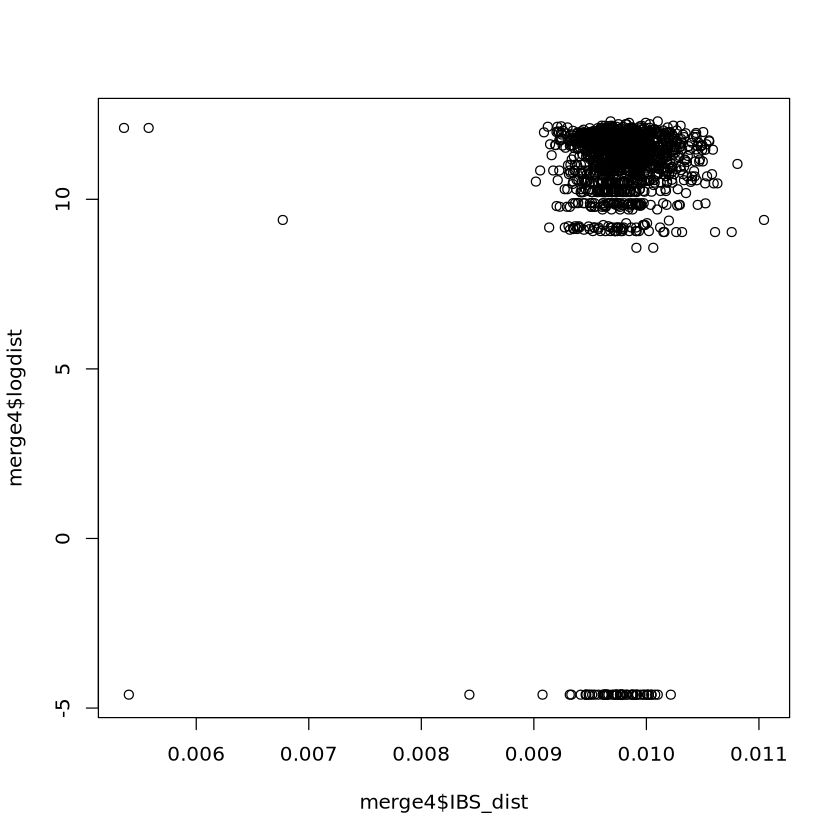

In [86]:
plot(merge4$IBS_dist,merge4$logdist)

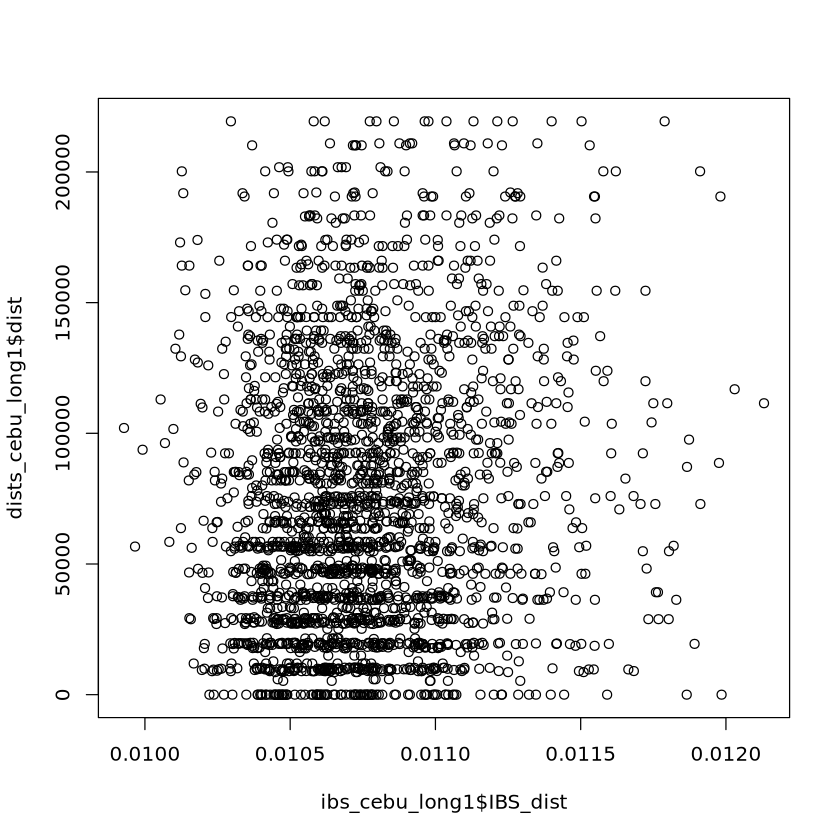

In [81]:
plot(ibs_cebu_long1$IBS_dist,dists_cebu_long1$dist)

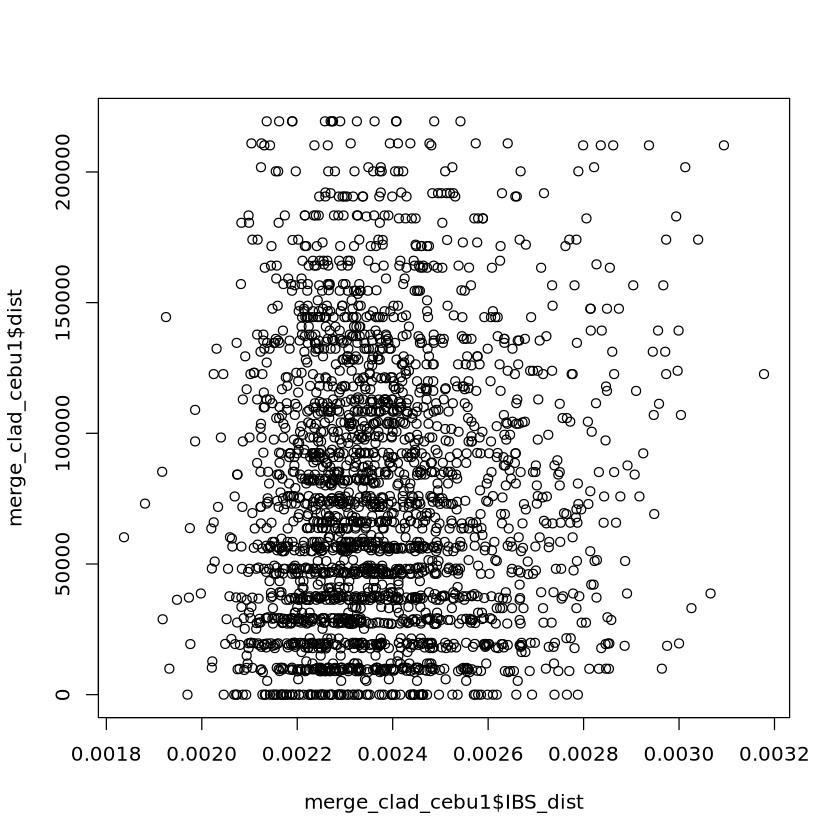

In [84]:
plot(merge_clad_cebu1$IBS_dist,merge_clad_cebu1$dist)

In [119]:
#Calculate confidence intervals around slopes for plotting
slope_min1<-quantile(m1s,probs=c(0.025))
slope_max1<-quantile(m1s,probs=c(0.975))
intercept1<-lm(IBS_dist ~ logdist, data = merge1)$coefficients[1]
value_mins1<-intercept1+slope_min1*merge1$logdist
value_maxs1<-intercept1+slope_max1*merge1$logdist
value_meds1<-intercept1+m1*merge1$logdist

slope_min2<-quantile(m2s,probs=c(0.025))
slope_max2<-quantile(m2s,probs=c(0.975))
intercept2<-lm(IBS_dist ~ logdist, data = merge2)$coefficients[1]
value_mins2<-intercept2+slope_min2*merge2$logdist
value_maxs2<-intercept2+slope_max2*merge2$logdist
value_meds2<-intercept2+m2*merge2$logdist

slope_min3<-quantile(m3s,probs=c(0.025))
slope_max3<-quantile(m3s,probs=c(0.975))
intercept3<-lm(IBS_dist ~ logdist, data = merge3)$coefficients[1]
value_mins3<-intercept3+slope_min3*merge3$logdist
value_maxs3<-intercept3+slope_max3*merge3$logdist
value_meds3<-intercept3+m3*merge3$logdist

slope_min4<-quantile(m4s,probs=c(0.025))
slope_max4<-quantile(m4s,probs=c(0.975))
intercept4<-lm(IBS_dist ~ logdist, data = merge4)$coefficients[1]
value_mins4<-intercept4+slope_min4*merge4$logdist
value_maxs4<-intercept4+slope_max4*merge4$logdist
value_meds4<-intercept4+m4*merge4$logdist

In [118]:
#Calculate confidence intervals around slopes for plotting, Cebu only
slope_min1_Cebu<-quantile(m1s_ceb,probs=c(0.025))
slope_max1_Cebu<-quantile(m1s_ceb,probs=c(0.975))
intercept1_Cebu<-lm(IBS_dist ~ dist, data = merge_cebu1)$coefficients[1]
value_mins_Cebu1<-intercept1_Cebu+slope_min1_Cebu*merge_cebu1$dist
value_maxs_Cebu1<-intercept1_Cebu+slope_max1_Cebu*merge_cebu1$dist
value_meds_Cebu1<-intercept1_Cebu+m1_ceb*merge_cebu1$dist

slope_min2_Cebu<-quantile(m2s_ceb,probs=c(0.025))
slope_max2_Cebu<-quantile(m2s_ceb,probs=c(0.975))
intercept2_Cebu<-lm(IBS_dist ~ dist, data = merge_cebu2)$coefficients[1]
value_mins_Cebu2<-intercept2_Cebu+slope_min2_Cebu*merge_cebu2$dist
value_maxs_Cebu2<-intercept2_Cebu+slope_max2_Cebu*merge_cebu2$dist
value_meds_Cebu2<-intercept2_Cebu+m2_ceb*merge_cebu2$dist

slope_min3_Cebu<-quantile(m3s_ceb,probs=c(0.025))
slope_max3_Cebu<-quantile(m3s_ceb,probs=c(0.975))
intercept3_Cebu<-lm(IBS_dist ~ dist, data = merge_cebu3)$coefficients[1]
value_mins_Cebu3<-intercept3_Cebu+slope_min3_Cebu*merge_cebu3$dist
value_maxs_Cebu3<-intercept3_Cebu+slope_max3_Cebu*merge_cebu3$dist
value_meds_Cebu3<-intercept3_Cebu+m3_ceb*merge_cebu3$dist

slope_min4_Cebu<-quantile(m4s_ceb,probs=c(0.025))
slope_max4_Cebu<-quantile(m4s_ceb,probs=c(0.975))
intercept4_Cebu<-lm(IBS_dist ~ dist, data = merge_cebu4)$coefficients[1]
value_mins_Cebu4<-intercept4_Cebu+slope_min4_Cebu*merge_cebu4$dist
value_maxs_Cebu4<-intercept4_Cebu+slope_max4_Cebu*merge_cebu4$dist
value_meds_Cebu4<-intercept4_Cebu+m4_ceb*merge_cebu4$dist

Saving 7 x 7 in image


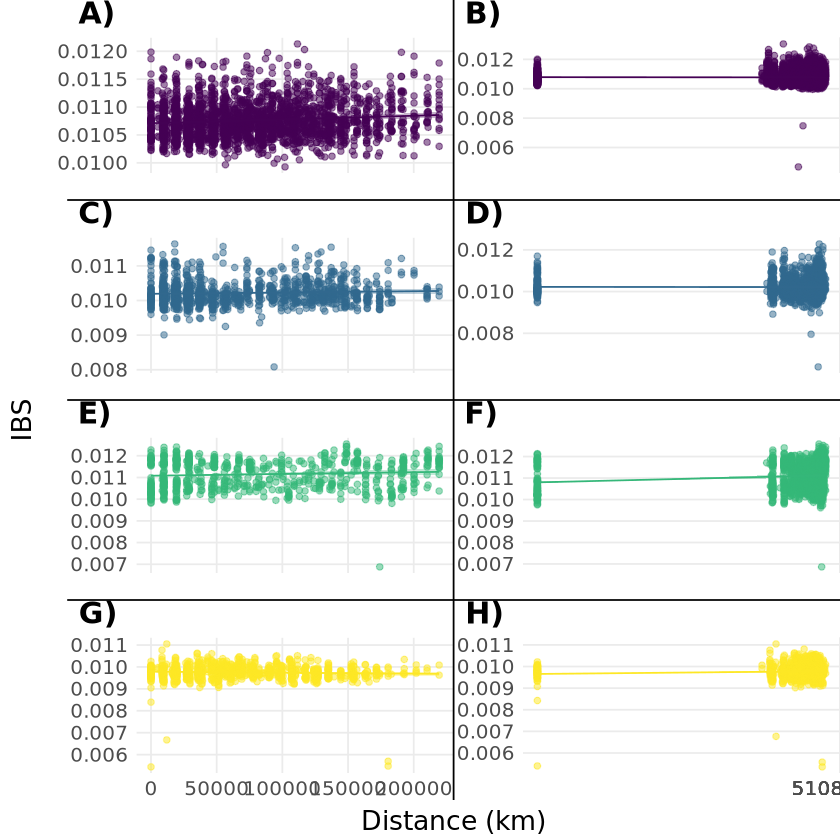

In [126]:
#Make figure of isolation in each taxon 2D
log10_plus_001 <- scales::trans_new(
  name = "log10_plus_001",
  transform = function(x) log10(x + 0.01),
  inverse = function(x) 10^x - 0.01,
  breaks = function(x) {
    rng <- range(x[is.finite(x) & x > 0], na.rm = TRUE)
    scales::log_breaks(base = 10)(rng)
  }
)

ibs_plot <- function(data, color, IBS_dist, dists, ribbon_meds, ribbon_mins, ribbon_maxs, log_scale=TRUE){
  pl <- ggplot(data, aes(x = as.numeric(dist), y = IBS_dist)) +
    geom_point(col=color, alpha=0.5) +
    geom_ribbon(aes(ymin = ribbon_mins, ymax = ribbon_maxs), fill=color, alpha=0.3) +
    geom_line(aes(y=ribbon_meds), col=color) +
    theme_minimal() +
    theme(axis.title.x = element_blank(),
          axis.title.y = element_blank(),
          axis.text.x = element_text(size=12),
          axis.text.y = element_text(size=12),
          plot.margin = unit(c(0.8, 0, 0, 0), "cm"),
          panel.grid.minor = element_blank(),
          legend.position = "none")
 if(log_scale) {
   pl <- pl + scale_x_continuous(trans = log10_plus_001)
 }
  return(pl)
}
  
# Create the eight plots
# Row 1 (A and B) - Taxa 1, no x-axis labels
plot_a <- ibs_plot(merge_cebu1, "#440154FF", IBS_dist=merge_cebu1$IBS_dist, dists=merge_cebu1$logdist, ribbon_meds=value_meds_Cebu1, ribbon_mins=value_mins_Cebu1, ribbon_maxs=value_maxs_Cebu1, log_scale=FALSE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

plot_b <- ibs_plot(merge1, "#440154FF", IBS_dist=merge1$IBS_dist, dists=merge1$logdist, ribbon_meds=value_meds1, ribbon_mins=value_mins1, ribbon_maxs=value_maxs1, log_scale=TRUE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

# Row 2 (C and D) - Taxa 2, no x-axis labels
plot_c <- ibs_plot(merge_cebu2, "#31688EFF", IBS_dist=merge_cebu2$IBS_dist, dists=merge_cebu2$logdist, ribbon_meds=value_meds_Cebu2, ribbon_mins=value_mins_Cebu2, ribbon_maxs=value_maxs_Cebu2, log_scale=FALSE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

plot_d <- ibs_plot(merge2, "#31688EFF", IBS_dist=merge2$IBS_dist, dists=merge2$logdist, ribbon_meds=value_meds2, ribbon_mins=value_mins2, ribbon_maxs=value_maxs2, log_scale=TRUE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

# Row 3 (E and F) - Taxa 3, no x-axis labels
plot_e <- ibs_plot(merge_cebu3, "#35B779FF", IBS_dist=merge_cebu3$IBS_dist, dists=merge_cebu3$logdist, ribbon_meds=value_meds_Cebu3, ribbon_mins=value_mins_Cebu3, ribbon_maxs=value_maxs_Cebu3, log_scale=FALSE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

plot_f <- ibs_plot(merge3, "#35B779FF", IBS_dist=merge3$IBS_dist, dists=merge3$logdist, ribbon_meds=value_meds3, ribbon_mins=value_mins3, ribbon_maxs=value_maxs3, log_scale=TRUE) +
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank())

# Row 4 (G and H) - Taxa 4, with x-axis labels
plot_g <- ibs_plot(merge_cebu4, "#FDE725FF", IBS_dist=merge_cebu4$IBS_dist, dists=merge_cebu4$logdist, ribbon_meds=value_meds_Cebu4, ribbon_mins=value_mins_Cebu4, ribbon_maxs=value_maxs_Cebu4, log_scale=FALSE) +
  coord_cartesian(clip = "off") +
  theme(plot.margin = unit(c(0.2, 0, 0, 0), "cm"))

plot_h <- ibs_plot(merge4, "#FDE725FF", IBS_dist=merge4$IBS_dist, dists=merge4$logdist, ribbon_meds=value_meds4, ribbon_mins=value_mins4, ribbon_maxs=value_maxs4, log_scale=TRUE)

# Combine plots using cowplot - 4 rows, 2 columns
combined_plot <- plot_grid(
  plot_a, plot_b,
  plot_c, plot_d,
  plot_e, plot_f,
  plot_g, plot_h,
  ncol = 2, 
  nrow = 4,
  labels = c("A)", "B)", "C)", "D)", "E)", "F)", "G)", "H)"),
  label_size = 18,
  label_colour = "black",
  label_x = 0.01,
  label_y = 0.86,
  align = "hv",
  rel_widths = c(1, 1),
  rel_heights = c(1, 1, 1, 1),
  hjust = -0.2,
  vjust = -0.2
)

# Add dividing lines between panels
combined_plot_with_lines <- ggdraw(combined_plot) +
  # Vertical line down the middle
  draw_line(x = c(0.5, 0.5), y = c(0, 1), color = "black", linewidth = 0.5) +
  # Horizontal lines
  draw_line(x = c(0, 1), y = c(0.75, 0.75), color = "black", linewidth = 0.5) +
  draw_line(x = c(0, 1), y = c(0.5, 0.5), color = "black", linewidth = 0.5) +
  draw_line(x = c(0, 1), y = c(0.25, 0.25), color = "black", linewidth = 0.5)

# Create a shared x-axis label for the bottom
x_axis_label <- ggdraw() + 
  draw_label("Distance (km)", 
             x = 0.5, y = 0.5, 
             size = 16,
             hjust = 0.5)

# Combine the plots with the shared x-axis label
plot_with_xlabel <- plot_grid(
  combined_plot_with_lines,
  x_axis_label,
  ncol = 1,
  rel_heights = c(1, 0.05)
)

# Add shared y-axis label
final_plot <- ggdraw() +
  draw_plot(plot_with_xlabel, x = 0.08, y = 0, width = 0.92, height = 1) +
  draw_label("IBS", 
             x = 0.025, y = 0.5,  
             angle = 90, 
             size = 16,
             hjust = 0.5)

# Display the combined plot
print(final_plot)
ggsave('/home/jbos/Philippines_revisions/IBD_from_IBS.jpg',final_plot)

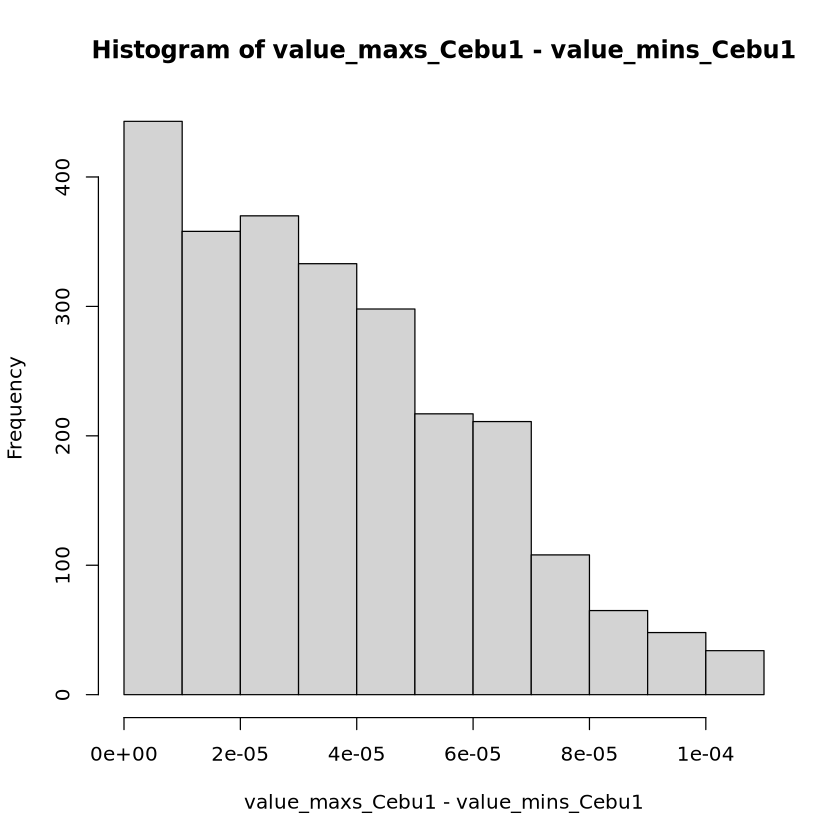

In [124]:
hist(value_maxs_Cebu1 - value_mins_Cebu1)

In [142]:
m1
m2
m3
m4

print('cebu')
m1_ceb
m2_ceb
m3_ceb
m4_ceb

[1] -9.045704e-07

[1] -6.366806e-07

[1] 1.905196e-05

[1] 7.567485e-06

[1] "cebu"


[1] 6.669817e-10

[1] 3.693241e-10

[1] 8.08131e-10

[1] -4.62191e-10

In [143]:
se1
se2
se3
se4

print('cebu')
se1_ceb
se2_ceb
se3_ceb
se4_ceb

[1] 1.384385e-06

[1] 2.447129e-06

[1] 4.232129e-06

[1] 2.978913e-06

[1] "cebu"


[1] 1.200862e-10

[1] 1.81392e-10

[1] 3.510813e-10

[1] 2.484069e-10

In [144]:
m1_clad
m2_clad
m3_clad
m4_clad

print('cebu')
m1_clad_ceb
m2_clad_ceb
m3_clad_ceb
m4_clad_ceb

[1] 3.420624e-06

[1] 3.876336e-06

[1] 6.303871e-06

[1] 7.795085e-06

[1] "cebu"


[1] 2.518368e-10

[1] 3.300493e-10

[1] 7.808084e-10

[1] 4.5304e-10

In [145]:
se1_clad
se2_clad
se3_clad
se4_clad

print('cebu')
se1_clad_ceb
se2_clad_ceb
se3_clad_ceb
se4_clad_ceb

[1] 8.26566e-07

[1] 1.209091e-06

[1] 1.560817e-06

[1] 1.832569e-06

[1] "cebu"


[1] 7.058476e-11

[1] 1.139951e-10

[1] 1.269601e-10

[1] 1.197167e-10